# Former CLOE vs cloelib at the analysis set-up: 13 bins, 32 $\ell$, $N_Z \geq 600$

`../speedcheck_reanalysis/speedcheck_reanalysis.ipynb` explained why the July 2026 speedcheck found former CLOE about 2x faster: a linear-bias + NLA model on a small problem (10 bins, 20 $\ell$, 100 redshift points), where cloelib's per-operation JAX overhead dominates. The analysis set-up is larger: **13 tomographic bins, 32 $\ell$ values and at least 600 redshift points**. This notebook times the two codes there, for both models:

| | **linear**: the speedcheck's model | **pt**: the model of `time_comparison_Euclid_DR3.ipynb` |
|---|---|---|
| galaxy bias | linear. cloelib: `"poly"` (cubic in $z$), CLOE: `bias_model: 1` (per-bin $b_1$, interpolated) | one-loop (FAST-PT). cloelib: `"nonlinear"` + `PBJNonlinearBiasLoopComputer`; CLOE: `NL_flag_phot_bias: 1` |
| intrinsic alignments | NLA (CLOE `IA_flag: 0`) | TATT (cloelib `PBJTATTLoopComputer`, CLOE `IA_flag: 1`) |
| matter $P(k)$ | CAMB Mead2020 | CAMB Mead2020 |

**Common set-up.**
- **Problem size:** 13 SPV3 bins (`nzTabSPV3.fits`, cut at $z\le3$), all 351 spectra (91 GG + 169 GE + 91 EE). $\ell$-grid `np.geomspace(2, 2999, 32)`. Same cosmology and nuisance values as the DR3 notebook.
- **Timed:** one full evaluation from scratch, CAMB excluded (the DR3 notebook's protocol). Median of 5, plus the first call; for cloelib the first call includes JAX compilation.
- **Redshift grids.** CAMB accepts at most 256 redshifts, so $N_Z = 600$ cannot be the P(k, z) grid. Both codes therefore use $N_Z$ points for $n(z)$, the kernels and the Limber integral, and $\min(N_Z, 250)$ points for the CAMB / perturbation-theory P(k, z) grid:
  - cloelib evaluates P(k) on the perturbations' grid and integrates on the tracers' grid;
  - CLOE gets `z_samp = min(N_Z, 250)`, and `Photo.z_grid_for_cl` / `z_winterp` are set to the $N_Z$ grid (`cloe_former_benchmark.py --n-z-pk`).
- **Versions.** cloelib `main` (`tp_paths.CLOELIB['main-0966dfa']`, `0966dfa`, 2026-10-09; it includes the non-linear bias of #596) and former CLOE (archived `main`, env `cloe-former`). The χ² is not timed for either code; it is one matrix-vector product with the same inverse covariance in both.
- **Scripts:** `cloelib_benchmark.py` and `cloe_former_benchmark.py`, each run as a subprocess.
- **CPUs:** run with `taskset -c 48-55`, 8 CPUs of NUMA node 1 of `drontermeer`, a laptop-sized budget. Socket 0 is throttled; see `time_comparison_Euclid_DR1.ipynb`.

> **In cloe-bench.** Executed on `drontermeer` (2026-10-09, 8 CPUs (48-55)) in a working directory outside this repository, then moved here. Since then only path handling has changed: locations come from `time_profiling/tp_paths.py`, results go to `results/` and figures to `figures/`. Local paths in the outputs are shown as `<WORKDIR>`. Set-up and re-running: `time_profiling/README.md`.


In [1]:
import json
import os
import subprocess
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
import euclidlib as el

import sys
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))   # time_profiling/, for tp_paths
import tp_paths as tp
RES, FIGURES = os.path.abspath('results'), os.path.abspath('figures')
os.makedirs(FIGURES, exist_ok=True)   # figures are not tracked in git
PY_CLOE = str(tp.PY_CLOE_FORMER)
PY_LIB = str(tp.PY_CLOE_COSMOSIS)
CLOELIB = 'main-0966dfa'                                       # key of tp.CLOELIB
tp.check(tp.CLOELIB[CLOELIB], tp.CLOE, tp.PY_CLOE_FORMER, tp.PY_CLOE_COSMOSIS, tp.NZ_SPV3)
CPUS = sorted(os.sched_getaffinity(0))
print(f'host {os.uname().nodename} | {len(CPUS)} CPUs: {CPUS[0]}-{CPUS[-1]} | load {os.getloadavg()[0]:.1f}')

NZ_VALUES = [100, 250, 600, 1000]   # n(z) / Limber points; P(k, z) grid min(N_Z, 250)
N_Z_PK = 250
NELL = 32
REPEAT = 5
MODELS = ('linear', 'pt')
ZMAX = 3.0

# CLOE reads its n(z) from a file: the 13 SPV3 bins resampled on each N_Z grid (cloelib does the same in memory)
z_all, nz_all = el.phz.redshift_distributions(str(tp.NZ_SPV3))
sel = z_all <= ZMAX
native = [v[sel] / integrate.trapezoid(v[sel], z_all[sel]) for v in nz_all.values()]
for n in NZ_VALUES:
    zs = np.linspace(1e-4, ZMAX, n)
    m = np.vstack([np.interp(zs, z_all[sel], v) for v in native])
    m /= integrate.trapezoid(m, zs, axis=1)[:, None]
    np.savetxt(os.path.join(tp.cloe_photometric_dir('SPV3_13bins'), f'nzTabSPV3_13bins_zs{n}.dat'),
               np.column_stack([zs, m.T]), delimiter='\t', header='z ' + ' '.join(f'n{i + 1}' for i in range(len(native))))


def run(name, cmd):
    out = os.path.join(RES, f'{name}.json')
    env = {**os.environ, 'TMPDIR': str(tp.TMP), 'PYTHONWARNINGS': 'ignore'}
    t0, load0 = time.time(), os.getloadavg()[0]
    proc = subprocess.run([*cmd, '--out', out], capture_output=True, text=True, env=env, cwd=str(tp.TP))
    with open(os.path.join(RES, f'{name}.log'), 'w') as f:
        f.write(proc.stdout + proc.stderr)
    assert proc.returncode == 0, proc.stderr[-3000:]
    for line in proc.stdout.splitlines():
        if line.startswith(('cloelib ', 'n_ell=')):
            print(line)
    print(f'   [{name}: {time.time() - t0:.0f} s, load {load0:.1f} -> {os.getloadavg()[0]:.1f}]')
    with open(out) as f:
        return json.load(f)

host drontermeer.strw.leidenuniv.nl | 8 CPUs: 48-55 | load 1.6


## 1. Timings

In [2]:
lib, cloe = {}, {}
for model in MODELS:
    lib[model] = run(f'cloelib_{model}', [PY_LIB, str(tp.CLOELIB_BENCHMARK), '--cloelib', CLOELIB, '--model', model,
                                          '--nell', str(NELL), '--n-z', *map(str, NZ_VALUES), '--n-z-pk', str(N_Z_PK),
                                          '--repeat', str(REPEAT)])
    for n in NZ_VALUES:
        cloe[model, n] = run(f'cloe_{model}_nz{n}', [PY_CLOE, str(tp.CLOE_FORMER_BENCHMARK), '--model', model,
                                                     '--nell', str(NELL), '--repeat', str(REPEAT), '--n-z', str(n),
                                                     '--n-z-pk', str(N_Z_PK), '--nz-file', f'nzTabSPV3_13bins_zs{n}.dat'])

cloelib linear N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.099 s | first call   2.16 s | 351 spectra
cloelib linear N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.128 s | first call   2.19 s | 351 spectra
cloelib linear N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.185 s | first call   2.27 s | 351 spectra
cloelib linear N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.173 s | first call   2.21 s | 351 spectra
   [cloelib_linear: 37 s, load 1.6 -> 3.1]


n_ell=   32 | CLOE from scratch   0.097s  first call   0.098s  (passing_requirements 0.001s, update_cosmo_dic 0.024s, create_photo_theory 0.072s) 351 spectra
   [cloe_linear_nz100: 29 s, load 3.1 -> 4.1]


n_ell=   32 | CLOE from scratch   0.179s  first call   0.181s  (passing_requirements 0.001s, update_cosmo_dic 0.059s, create_photo_theory 0.119s) 351 spectra
   [cloe_linear_nz250: 29 s, load 4.1 -> 4.9]


n_ell=   32 | CLOE from scratch   0.293s  first call   0.293s  (passing_requirements 0.001s, update_cosmo_dic 0.059s, create_photo_theory 0.232s) 351 spectra
   [cloe_linear_nz600: 27 s, load 4.9 -> 4.5]


n_ell=   32 | CLOE from scratch   0.542s  first call   0.558s  (passing_requirements 0.001s, update_cosmo_dic 0.059s, create_photo_theory 0.497s) 351 spectra
   [cloe_linear_nz1000: 35 s, load 4.5 -> 4.5]


cloelib pt     N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.236 s | first call   4.66 s | 351 spectra
cloelib pt     N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.340 s | first call   4.39 s | 351 spectra
cloelib pt     N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.477 s | first call   4.36 s | 351 spectra
cloelib pt     N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.510 s | first call   4.46 s | 351 spectra
   [cloelib_pt: 68 s, load 4.5 -> 6.1]


n_ell=   32 | CLOE from scratch   1.260s  first call   1.263s  (passing_requirements 0.001s, update_cosmo_dic 1.176s, create_photo_theory 0.072s) 351 spectra
   [cloe_pt_nz100: 43 s, load 6.1 -> 5.1]


n_ell=   32 | CLOE from scratch   2.140s  first call   2.154s  (passing_requirements 0.001s, update_cosmo_dic 2.020s, create_photo_theory 0.119s) 351 spectra
   [cloe_pt_nz250: 62 s, load 5.1 -> 4.2]


n_ell=   32 | CLOE from scratch   2.252s  first call   2.262s  (passing_requirements 0.001s, update_cosmo_dic 2.020s, create_photo_theory 0.231s) 351 spectra
   [cloe_pt_nz600: 56 s, load 4.2 -> 3.7]


n_ell=   32 | CLOE from scratch   2.458s  first call   2.464s  (passing_requirements 0.001s, update_cosmo_dic 2.026s, create_photo_theory 0.435s) 351 spectra
   [cloe_pt_nz1000: 54 s, load 3.7 -> 3.1]


In [3]:
t_lib = {(m, n): lib[m]['from_scratch'][str(n)][str(NELL)] for m in MODELS for n in NZ_VALUES}
f_lib = {(m, n): lib[m]['first_call'][str(n)][str(NELL)] for m in MODELS for n in NZ_VALUES}
t_cloe = {(m, n): cloe[m, n]['from_scratch'][str(NELL)] for m in MODELS for n in NZ_VALUES}
parts = {(m, n): cloe[m, n]['parts'][str(NELL)] for m in MODELS for n in NZ_VALUES}

print(f'One full 3x2pt evaluation from scratch, CAMB excluded: 13 bins, 351 spectra, n_ell = {NELL}, '
      f'median of {REPEAT}, {len(CPUS)} CPUs\n')
for m in MODELS:
    print(f'model = {m}')
    print(f'  {"N_Z":>5s} {"P(k,z)":>7s} {"cloelib":>9s} {"(first)":>8s} {"CLOE":>9s}   {"CLOE/cloelib":>12s}   '
          f'CLOE steps: update_cosmo_dic, create_photo_theory')
    for n in NZ_VALUES:
        p = parts[m, n]
        print(f'  {n:5d} {min(n, N_Z_PK):7d} {t_lib[m, n]:8.3f}s {f_lib[m, n]:7.1f}s {t_cloe[m, n]:8.3f}s   '
              f'{t_cloe[m, n] / t_lib[m, n]:11.1f}x   {p["update_cosmo_dic"]:.3f} s, {p["create_photo_theory"]:.3f} s')
    print()

One full 3x2pt evaluation from scratch, CAMB excluded: 13 bins, 351 spectra, n_ell = 32, median of 5, 8 CPUs

model = linear
    N_Z  P(k,z)   cloelib  (first)      CLOE   CLOE/cloelib   CLOE steps: update_cosmo_dic, create_photo_theory
    100     100    0.099s     2.2s    0.097s           1.0x   0.024 s, 0.072 s
    250     250    0.128s     2.2s    0.179s           1.4x   0.059 s, 0.119 s
    600     250    0.185s     2.3s    0.293s           1.6x   0.059 s, 0.232 s
   1000     250    0.173s     2.2s    0.542s           3.1x   0.059 s, 0.497 s

model = pt
    N_Z  P(k,z)   cloelib  (first)      CLOE   CLOE/cloelib   CLOE steps: update_cosmo_dic, create_photo_theory
    100     100    0.236s     4.7s    1.260s           5.3x   1.176 s, 0.072 s
    250     250    0.340s     4.4s    2.140s           6.3x   2.020 s, 0.119 s
    600     250    0.477s     4.4s    2.252s           4.7x   2.020 s, 0.231 s
   1000     250    0.510s     4.5s    2.458s           4.8x   2.026 s, 0.435 s



**Result: at the analysis set-up, cloelib is faster for both models.**

| $N_Z$ | linear + NLA: cloelib / CLOE | ratio | one-loop + TATT: cloelib / CLOE | ratio |
|---|---|---|---|---|
| 100 | 0.10 / 0.10 s | 1.0x | 0.24 / 1.26 s | 5.3x |
| 250 | 0.13 / 0.18 s | 1.4x | 0.34 / 2.14 s | 6.3x |
| **600** | **0.19 / 0.29 s** | **1.6x** | **0.48 / 2.25 s** | **4.7x** |
| 1000 | 0.17 / 0.54 s | 3.1x | 0.51 / 2.46 s | 4.8x |

The ratio column is CLOE time divided by cloelib time.

- **The speedcheck's 2x for CLOE does not survive the larger problem.** With 13 bins instead of 10, 32 $\ell$ instead of 20, and 600 redshift points instead of 100, the linear model costs CLOE 0.29 s and cloelib 0.19 s.
  - CLOE's C$_\ell$ step (`create_photo_theory`) grows linearly with $N_Z$: 0.07 → 0.23 → 0.50 s from 100 to 600 to 1000 points.
  - cloelib's cost is still largely its fixed per-operation overhead, so it grows much more slowly: 0.10 → 0.19 s.
  - At $N_Z = 100$, the two codes tie.
- **With the perturbation-theory model, cloelib is about 5x faster at every $N_Z$.** CLOE spends 2.0 s per evaluation in `update_cosmo_dic` rebuilding its FAST-PT objects on the 250-point P(k, z) grid (1.2 s on 100 points).
- **cloelib's one-off JAX compilation** is 2.2 s (linear) and 4.4 s (pt) per array shape, on top of the first call. At $N_Z = 600$ it is recovered after about 20 evaluations against CLOE for the linear model, and 2–3 for pt.
- **Noise:** the cloelib medians below 0.3 s scatter by about ±30% between runs. For example, the linear model at $N_Z = 600$ took 0.13 s in a separate test and 0.19 s here, which is also why 1000 points comes out slightly faster than 600. Differences under 0.1 s are not significant.

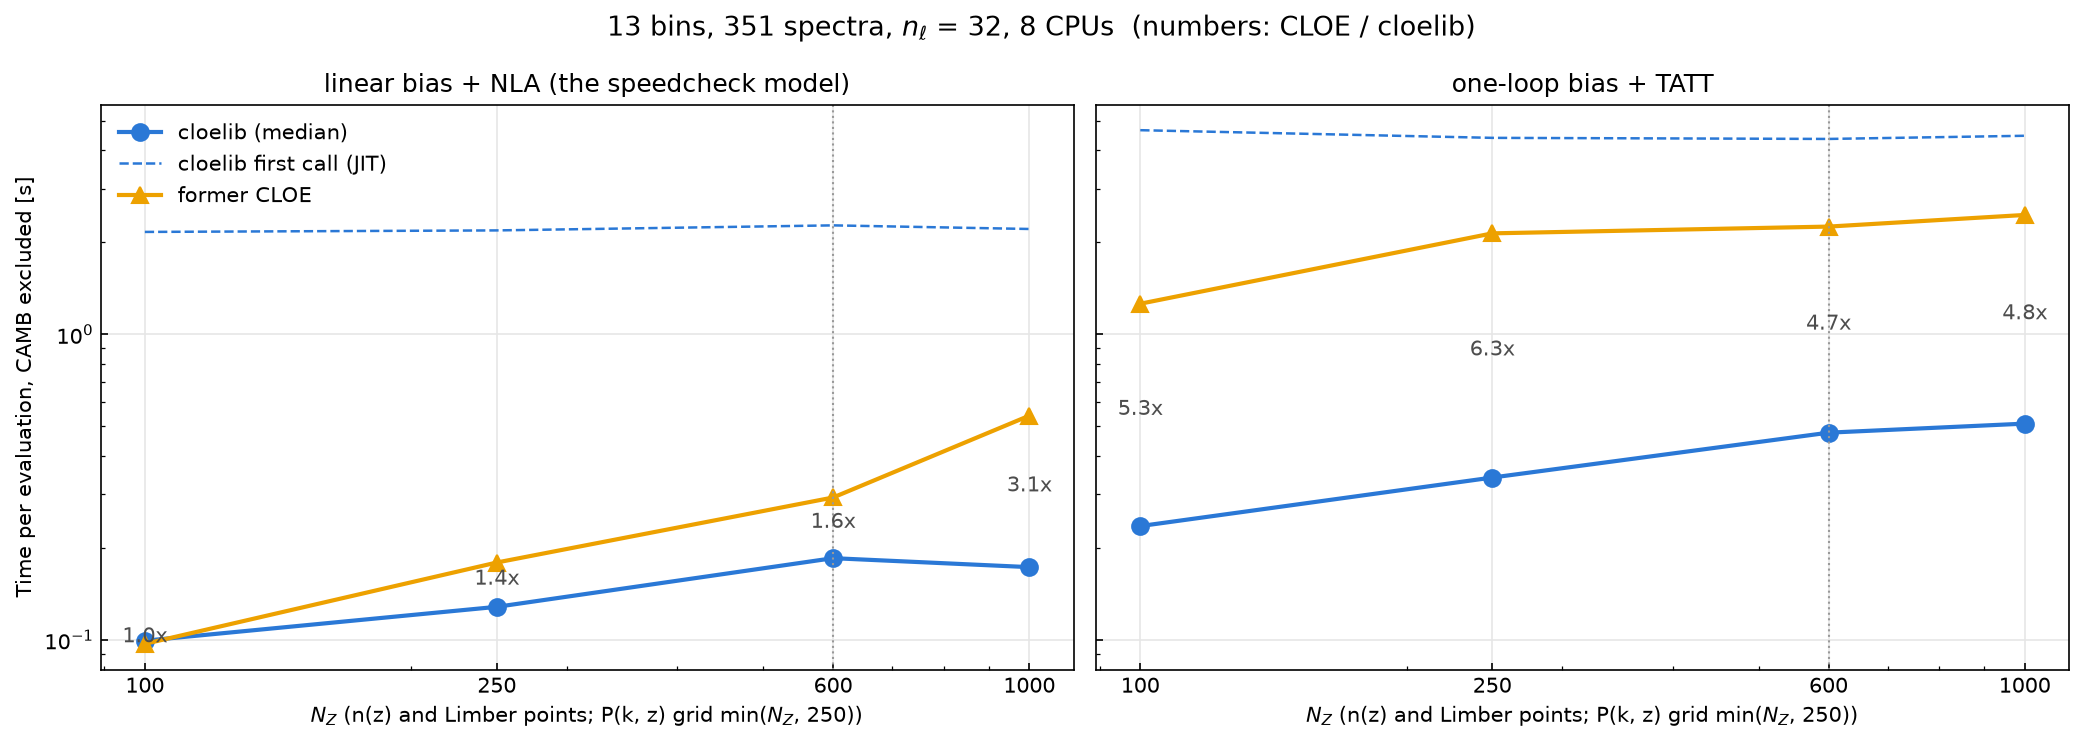

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
COL = {'cloelib': '#2a78d6', 'CLOE (former)': '#eda100'}
for ax, m, title in zip(axes, MODELS, ('linear bias + NLA (the speedcheck model)', 'one-loop bias + TATT')):
    x = np.array(NZ_VALUES)
    ax.plot(x, [t_lib[m, n] for n in NZ_VALUES], 'o-', color=COL['cloelib'], lw=2, ms=8, label='cloelib (median)')
    ax.plot(x, [f_lib[m, n] for n in NZ_VALUES], '--', color=COL['cloelib'], lw=1.2, label='cloelib first call (JIT)')
    ax.plot(x, [t_cloe[m, n] for n in NZ_VALUES], '^-', color=COL['CLOE (former)'], lw=2, ms=8, label='former CLOE')
    for n in NZ_VALUES:
        ax.annotate(f'{t_cloe[m, n] / t_lib[m, n]:.1f}x', (n, np.sqrt(t_cloe[m, n] * t_lib[m, n])), ha='center',
                    fontsize=10, color='0.3')
    ax.axvline(600, color='0.6', lw=1, ls=':')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xticks(NZ_VALUES); ax.set_xticklabels(NZ_VALUES)
    ax.set_xlabel('$N_Z$ (n(z) and Limber points; P(k, z) grid min($N_Z$, 250))')
    ax.set_title(title, fontsize=12)
    ax.grid(True, which='major', color='0.9')
    ax.tick_params(direction='in', which='both')
axes[0].set_ylabel('Time per evaluation, CAMB excluded [s]')
axes[0].legend(frameon=False, fontsize=10, loc='upper left')
fig.suptitle(f'13 bins, 351 spectra, $n_\\ell$ = {NELL}, {len(CPUS)} CPUs  (numbers: CLOE / cloelib)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'time_comparison_cloe_vs_cloelib_13bins.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. Summary
At the analysis set-up (13 bins, 32 $\ell$, $N_Z = 600$; 8 CPUs), cloelib is **1.6x faster than former CLOE for linear bias + NLA**, the speedcheck's model, and **4.7x faster for one-loop bias + TATT**. The cloelib advantage grows with $N_Z$ for the linear model, because CLOE's C$_\ell$ step scales with the number of redshift points.

The speedcheck's result (CLOE about 2x faster) is specific to its small problem (10 bins, 20 $\ell$, 100 points), where cloelib's per-operation JAX overhead outweighs the arithmetic. It also used a June-2026 cloelike that ran CAMB three times per evaluation. See `../speedcheck_reanalysis/speedcheck_reanalysis.ipynb`.

**Caveats:**
- The CAMB P(k, z) grid is capped at 250 redshifts in both codes, because CAMB accepts at most 256. The 600 points apply to $n(z)$, the kernels and the Limber integral.
- The χ² is not timed. It is the same matrix-vector product in both codes: for 351 spectra × 32 $\ell$ = 11,232 data points, about 0.1 s at most, so it would slightly reduce the ratios.
- The bias parametrisation differs slightly between the codes in the linear model (cloelib polynomial, CLOE per-bin $b_1$). That changes values, not cost.